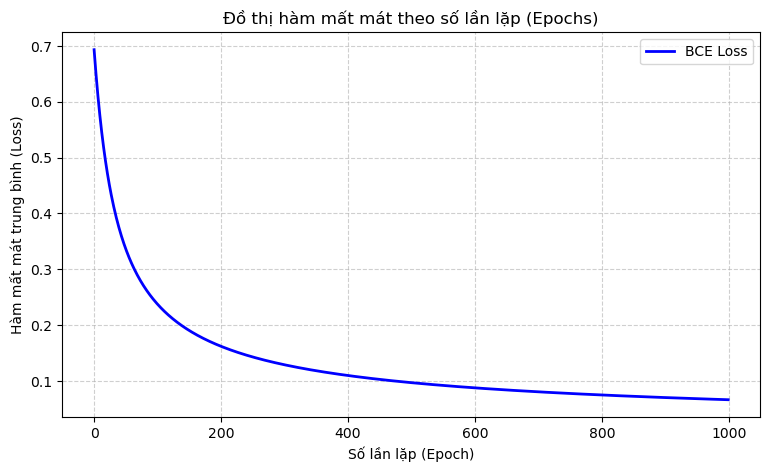

Sau 1000 lần lặp: w = 7.6703, b = 0.7685, Loss cuối cùng = 0.0663


In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Khai báo dữ liệu gốc từ Bài 2
x = np.array([132, 141, 88, 154, 151, 102, 119, 106, 102, 143, 76, 168, 94, 186])
y = np.array([1, 1, 0, 1, 1, 0, 0, 0, 0, 1, 0, 1, 0, 1])

# Chuẩn hóa đặc trưng thời lượng phim
x_prime = (x - 130) / 50.0
m = len(y)

# 2. Khởi tạo tham số và siêu tham số
w = 0.0
b = 0.0
alpha = 0.2
epochs = 1000

loss_history = []

# 3. Quá trình huấn luyện Batch Gradient Descent
for epoch in range(epochs):
    # Forward Pass
    z = w * x_prime + b
    y_hat = 1.0 / (1.0 + np.exp(-z))
    
    # Tính Binary Cross-Entropy Loss (cộng thêm epsilon nhỏ tránh lỗi log(0))
    loss = -np.mean(y * np.log(y_hat + 1e-15) + (1 - y) * np.log(1 - y_hat + 1e-15))
    loss_history.append(loss)
    
    # Backward Pass (Tính Gradient)
    dw = np.mean((y_hat - y) * x_prime)
    db = np.mean(y_hat - y)
    
    # Cập nhật tham số
    w -= alpha * dw
    b -= alpha * db

# 4. Vẽ đồ thị hàm mất mát theo số lần lặp
plt.figure(figsize=(9, 5))
plt.plot(range(epochs), loss_history, color='blue', linewidth=2, label='BCE Loss')
plt.title('Đồ thị hàm mất mát theo số lần lặp (Epochs)')
plt.xlabel('Số lần lặp (Epoch)')
plt.ylabel('Hàm mất mát trung bình (Loss)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

# In kết quả cuối cùng
print(f"Sau {epochs} lần lặp: w = {w:.4f}, b = {b:.4f}, Loss cuối cùng = {loss_history[-1]:.4f}")